# Supplementary Validation 01: Doplňující ověření validace a regresního experimentu (Supplementary Validation)

**Habilitační práce:** Metodologie generování a validace dat pro modely umělé inteligence ve stavebním inženýrství

**Verze:** 1.0  **Datum:** 2026-11-16  **Autor:** Vjačeslav Usmanov, ČVUT v Praze, Fakulta stavební

## Popis

Notebook obsahuje doplňující výpočty provedené **po odevzdání habilitační práce** jako podklad k obhajobě. Výsledky uvedené v práci a v Přílohách 1–6 nemění. Původní notebooky zůstávají beze změny.

Notebook odpovídá na pět otázek:

| Část | Otázka | Navazuje na |
|---|---|---|
| 1 | Lze zopakovat hodnoty uvedené v práci? | Přílohy 4, 5 a 6 |
| 2 | Jak vyjde test K–S, když se model před kalibrací a po ní porovná stejným způsobem? | kap. 4.5 a 4.6, Přílohy 4 a 5 |
| 3 | Jak se model před kalibrací shoduje s měřením ve stejném rozsahu trajektorií? | kap. 4.5, Příloha 4 |
| 4 | Jak se změní shoda, když generátor syntetických dat přičte reziduální šum σ? | kap. 4.6, Příloha 5 |
| 5 | Je zlepšení regresního modelu stabilní pro různá náhodná rozdělení a způsobuje ho složení dat, nebo jen jejich množství? | kap. 4.7, Příloha 6 |

## Vstupní data

| Soubor | Obsah |
|---|---|
| `data/02_DetermModel/model_data_real.csv` | reálné cykly použité ke kalibraci (161) |
| `data/06_AI/train/train_timelaps.csv` | tytéž reálné cykly pro regresní experiment (161) |
| `data/06_AI/val/valid_timelaps.csv` | nezávislé reálné cykly (108) |
| `data/04_HybridModel/hybrid_model.csv` | simulace hybridního modelu před kalibrací (20 000 cyklů) |
| `data/05_Calibration/synthetic_dataset.csv` | syntetická data z práce (500 000 záznamů) |
| `data/05_Calibration/posterior_three.csv` | posteriorní vzorky kalibrovaných parametrů |

## Výstupy

Tabulky ve formátu CSV a obrázky ve formátu PNG se ukládají do složky `data/07_Supplement/`.

## Legenda

| Označení | Význam |
|---|---|
| `dist` | délka trajektorie od referenčního bodu k cílové poloze prvku [mm] |
| `time` | doba pracovního cyklu bez zdržení [s] |
| `delay`, `stochastic_delay` | zdržení v cyklu [s] |
| `total_time` | celková doba pracovního cyklu včetně zdržení [s] |
| σ (`sigma`) | reziduální šum odhadnutý bayesovskou kalibrací [s] |
| K–S | dvouvýběrový Kolmogorovův–Smirnovův test shody rozdělení |
| podíl bez zamítnutí | podíl opakování, ve kterých K–S test nezamítl shodu na hladině 0,05 |
| velikost podvzorku | počet záznamů vybraných z modelu pro jedno opakování K–S testu |
| Welch p, M–W p | p-hodnota Welchova t-testu (průměr) a Mannova–Whitneyho U testu (medián) |
| Cohen d | velikost efektu rozdílu průměrů |
| sd | výběrová směrodatná odchylka |
| pokrytí | podíl reálných cyklů uvnitř 95% intervalu modelu (očekává se přibližně 95 %) |
| celý rozsah / stejný rozsah | simulace se všemi trajektoriemi / jen s trajektoriemi v rozsahu reálných dat |
| bez šumu / se šumem σ | generátor podle Přílohy 5 / generátor doplněný o reziduální šum |
| přidávání | reálná trénovací data zůstávají, syntetická se přidávají (postup z práce) |
| stálá velikost | velikost trénovací sady se nemění, reálná data se nahrazují syntetickými |
| R², RMSE | koeficient determinace a odmocnina střední kvadratické chyby na nezávislých reálných cyklech |

In [1]:
# Instalace potřebných knihoven
#%pip install pandas
#%pip install numpy
#%pip install scipy
#%pip install scikit-learn
#%pip install matplotlib

In [2]:
# Import potřebných knihoven
import os
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, ttest_ind, mannwhitneyu
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

for nazev, modul in [('pandas', pd), ('numpy', np), ('scipy', scipy), ('scikit-learn', sklearn), ('matplotlib', matplotlib)]:
    print(f'{nazev}: {modul.__version__}')

pandas: 2.2.2
numpy: 1.26.4
scipy: 1.13.1
scikit-learn: 1.5.1
matplotlib: 3.9.2


## Nastavení výpočtu

In [3]:
# Složky
DATA = '../../data'
OUT = f'{DATA}/07_Supplement'
os.makedirs(OUT, exist_ok=True)

# Test K–S
N_OPAKOVANI = 1000              # počet opakování bootstrapu
VELIKOSTI = [36, 54, 108]       # velikost podvzorku z modelu
SEED = 122                      # stejný seed jako v původních noteboocích

# Generátor syntetických dat
M_SYN = 500_000                 # počet nově generovaných syntetických cyklů

# Regresní experiment
N_SEEDU = 30                    # počet náhodných rozdělení
PODILY = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]
PODILY_STALA = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

## Pomocné funkce

Funkce `calculation_dist`, `simulate_time` a `remove_outliers_iqr` jsou převzaty z Příloh 5 a 6.

In [4]:
def calculation_dist(x, y, z, brick_thickness=440, brick_height=250, brick_width=250,
                     refer_x=2000, refer_y=3500, refer_z=1000):
    """Dráha trajektorie od referenčního bodu k cílové poloze prvku [mm] (Příloha 5 a 6)."""
    dist = ((refer_z - (z + brick_height*2))**2 + (refer_x - brick_thickness//2)**2)**(1/2)
    if x != brick_thickness / 2:
        dist = dist + abs(x - brick_thickness//2 + brick_width * 2)
    if y != brick_thickness / 2:
        dist = dist + abs(y - refer_y + brick_width * 2)
    return int(dist)

def simulate_time(dist, v_load, v_unload, accel, time_refer_2_refer=20, time_mounting=3):
    """Doba pracovního cyklu bez zdržení [s]; stejný výpočet jako v CM_02_SyntGenerator, vektorově."""
    t_l = v_load / accel;   d_l = 0.5 * accel * t_l
    t_u = v_unload / accel; d_u = 0.5 * accel * t_u
    return (time_refer_2_refer + time_mounting + (dist - d_l) / 1000 / v_load
            + (dist - d_u) / 1000 / v_unload + t_l + t_u)

def ks_podil(model_t, real_t, n, zpusob='numpy'):
    """Podíl opakování [%], ve kterých K–S test nezamítl shodu (p > 0,05).

    zpusob='pandas' vybírá podvzorky stejně jako původní notebooky (DataFrame.sample),
    zpusob='numpy' je rychlejší varianta pro nově generovaná data."""
    p = []
    for i in range(N_OPAKOVANI):
        if zpusob == 'pandas':
            vzorek = model_t.sample(n=n, replace=True, random_state=SEED + i)
        else:
            vzorek = np.random.default_rng(SEED + i).choice(np.asarray(model_t, float), n)
        p.append(ks_2samp(real_t, vzorek)[1])
    return 100 * np.mean(np.array(p) > 0.05)

def porovnej(model_t, real_t):
    """Základní porovnání modelu s reálnými daty: průměr, sd, Welch, Mann–Whitney, Cohen d."""
    model_t, real_t = np.asarray(model_t, float), np.asarray(real_t, float)
    d = abs(real_t.mean() - model_t.mean()) / np.sqrt((real_t.std(ddof=1)**2 + model_t.std(ddof=1)**2) / 2)
    return {'průměr [s]': model_t.mean(), 'sd [s]': model_t.std(ddof=1),
            'Welch p': ttest_ind(real_t, model_t, equal_var=False).pvalue,
            'M–W p': mannwhitneyu(real_t, model_t).pvalue, 'Cohen d': d}

def model_poly():
    """Polynomiální regrese 3. stupně (Příloha 6)."""
    return Pipeline([('poly', PolynomialFeatures(degree=3)), ('lin', LinearRegression())])

def remove_outliers_iqr(df):
    """Odstranění odlehlých hodnot podle reziduí regrese, pravidlo 1,5 IQR (Příloha 6)."""
    m = model_poly().fit(df[['dist']], df['total_time'])
    res = df['total_time'] - m.predict(df[['dist']])
    q1, q3 = res.quantile(0.25), res.quantile(0.75)
    return df[(res >= q1 - 1.5*(q3 - q1)) & (res <= q3 + 1.5*(q3 - q1))]

## Vstupní data

In [5]:
# Reálná data
real_train = pd.read_csv(f'{DATA}/02_DetermModel/model_data_real.csv')       # kalibrační cykly (161)
real_val = pd.read_csv(f'{DATA}/06_AI/val/valid_timelaps.csv')               # nezávislé cykly (108)
real_val['dist'] = real_val.apply(lambda r: calculation_dist(r['x'], r['y'], r['z']), axis=1)

# Model před kalibrací a po kalibraci
sim = pd.read_csv(f'{DATA}/04_HybridModel/hybrid_model.csv')                 # hybridní simulace (20 000)
syn = pd.read_csv(f'{DATA}/05_Calibration/synthetic_dataset.csv')            # syntetická data z práce
post = pd.read_csv(f'{DATA}/05_Calibration/posterior_three.csv')             # posteriorní vzorky

# Omezení na rozsah trajektorií validačních dat
d_min, d_max = real_val['dist'].min(), real_val['dist'].max()
sim_rozsah = sim[(sim['dist'] >= d_min) & (sim['dist'] <= d_max)]
syn_rozsah = syn[(syn['dist'] >= d_min) & (syn['dist'] <= d_max)]

prehled = pd.DataFrame({
    'počet': [len(real_train), len(real_val), len(sim), len(sim_rozsah), len(syn), len(syn_rozsah)],
    'dist min [mm]': [d['dist'].min() for d in (real_train, real_val, sim, sim_rozsah, syn, syn_rozsah)],
    'dist max [mm]': [d['dist'].max() for d in (real_train, real_val, sim, sim_rozsah, syn, syn_rozsah)],
    'průměr total_time [s]': [d['total_time'].mean() for d in (real_train, real_val, sim, sim_rozsah, syn, syn_rozsah)],
}, index=['reálná kalibrační', 'reálná validační', 'simulace před kalibrací', 'simulace, stejný rozsah',
          'syntetická data z práce', 'syntetická, stejný rozsah'])
prehled.round(2)

,počet,dist min [mm],dist max [mm],průměr total_time [s]
reálná kalibrační,161,1840,6609,41.99
reálná validační,108,1908,6466,41.80
simulace před kalibrací,20000,1984,10789,46.49
"simulace, stejný rozsah",11848,1984,6466,41.14
syntetická data z práce,500000,1200,6600,40.69
"syntetická, stejný rozsah",422449,1908,6465,41.38


## Část 1: Reprodukce hodnot uvedených v práci

Kontrola, že notebook pracuje se stejnými daty a stejným postupem jako Přílohy 4 a 5. Očekávané hodnoty: **0,0 %** před kalibrací a **75,2 %** po kalibraci.

In [6]:
ks_puvodni = pd.DataFrame({
    'porovnání': ['před kalibrací: simulace proti kalibračním datům',
                  'po kalibraci: syntetická data proti validačním datům'],
    'velikost podvzorku': [len(real_train), len(real_val) // 3],
    'podíl bez zamítnutí [%]': [
        ks_podil(sim['total_time'], real_train['total_time'], len(real_train), zpusob='pandas'),
        ks_podil(syn_rozsah['total_time'], real_val['total_time'], len(real_val) // 3, zpusob='pandas')],
})
ks_puvodni

,porovnání,velikost podvzorku,podíl bez zamítnutí [%]
0,před kalibrací: simulace proti kalibračním datům,161,0.0
1,po kalibraci: syntetická data proti validačním...,36,75.2


## Část 2: Test K–S se stejným nastavením

V práci se test K–S před kalibrací a po ní lišil ve třech ohledech: ve velikosti podvzorku (161 a 36), v referenčních reálných datech (kalibrační a validační) a v rozsahu trajektorií (simulace před kalibrací nebyla omezena na rozsah reálných dat).

Zde se obě verze modelu porovnávají **proti stejným 108 validačním cyklům** a se **stejnou velikostí podvzorku**.

In [7]:
radky = []
for n in VELIKOSTI:
    radky.append({
        'velikost podvzorku': n,
        'před kalibrací, celý rozsah [%]':   ks_podil(sim['total_time'], real_val['total_time'], n, zpusob='pandas'),
        'před kalibrací, stejný rozsah [%]': ks_podil(sim_rozsah['total_time'], real_val['total_time'], n, zpusob='pandas'),
        'po kalibraci [%]':                  ks_podil(syn_rozsah['total_time'], real_val['total_time'], n, zpusob='pandas'),
    })
ks_stejne = pd.DataFrame(radky).set_index('velikost podvzorku')
ks_stejne.to_csv(f'{OUT}/SV_01_ks_stejne_nastaveni.csv')
ks_stejne.round(1)

,"před kalibrací, celý rozsah [%]","před kalibrací, stejný rozsah [%]",po kalibraci [%]
velikost podvzorku,,,
36,16.8,83.3,75.2
54,4.0,67.3,47.9
108,0.0,7.0,0.2


## Část 3: Model před kalibrací ve stejném rozsahu trajektorií

Simulace před kalibrací obsahuje i trajektorie delší než reálná data. Porovnání průměru, mediánu a velikosti efektu je proto provedeno pro celý rozsah (jako v Příloze 4) a pro stejný rozsah trajektorií jako reálná data.

Očekávané hodnoty pro celý rozsah proti kalibračním datům: Welch p = 0,037, Cohen d = 0,184.

In [8]:
radky = []
for nazev, real in [('kalibrační (161)', real_train), ('validační (108)', real_val)]:
    v_rozsahu = sim[(sim['dist'] >= real['dist'].min()) & (sim['dist'] <= real['dist'].max())]
    for rozsah, model in [('celý rozsah', sim), ('stejný rozsah', v_rozsahu)]:
        radky.append({'reálná data': nazev, 'simulace': rozsah,
                      'reálný průměr [s]': real['total_time'].mean(), 'reálná sd [s]': real['total_time'].std(),
                      **porovnej(model['total_time'], real['total_time'])})
pred_kalibraci = pd.DataFrame(radky).set_index(['reálná data', 'simulace'])
pred_kalibraci.to_csv(f'{OUT}/SV_01_pred_kalibraci_rozsah.csv')
pred_kalibraci.round(4)

reálný průměr [s]  reálná sd [s]  průměr [s]  \
reálná data      simulace                                                      
kalibrační (161) celý rozsah              41.9938        27.0374     46.4864   
                 stejný rozsah            41.9938        27.0374     41.3575   
validační (108)  celý rozsah              41.7963        28.4584     46.4864   
                 stejný rozsah            41.7963        28.4584     41.1395   

                                 sd [s]  Welch p   M–W p  Cohen d  
reálná data      simulace                                          
kalibrační (161) celý rozsah    21.4018   0.0370  0.0000   0.1843  
                 stejný rozsah  18.9160   0.7663  0.0026   0.0273  
validační (108)  celý rozsah    21.4018   0.0901  0.0000   0.1863  
                 stejný rozsah  18.8146   0.8113  0.1004   0.0272

## Část 4: Generátor syntetických dat s reziduálním šumem

Model v kap. 4.6 obsahuje reziduální složku ε ~ N(0, σ²). Generátor v Příloze 5 ji nepřičítal. Zde se generují dvě varianty syntetických dat pro trajektorie v rozsahu validačních dat:

- **bez šumu:** doba cyklu = fyzikální model + zdržení (postup z Přílohy 5),
- **se šumem σ:** doba cyklu = fyzikální model + zdržení + reziduální šum.

Hodnota σ pochází z kalibrace na 161 kalibračních cyklech. Na validačních datech laděna nebyla.

In [9]:
rng = np.random.default_rng(SEED)
dist = rng.integers(d_min, d_max + 1, M_SYN)
i = rng.integers(0, len(post), M_SYN)
T_det = simulate_time(dist, post['v_load'].to_numpy()[i], post['v_unload'].to_numpy()[i], post['accel'].to_numpy()[i])
zdrzeni = rng.choice(sim['stochastic_delay'].to_numpy(), M_SYN)
sum_ = rng.normal(0, post['sigma'].to_numpy()[i])

varianty = {'bez šumu': T_det + zdrzeni, 'se šumem σ': T_det + zdrzeni + sum_}
real_t = real_val['total_time'].to_numpy(float)

print(f'Reálná validační data: průměr {real_t.mean():.2f} s, sd {real_t.std(ddof=1):.2f} s')
generator = pd.DataFrame({nazev: porovnej(t, real_t) for nazev, t in varianty.items()}).T
for n in VELIKOSTI:
    generator[f'K–S bez zamítnutí, n = {n} [%]'] = [ks_podil(t, real_t, n) for t in varianty.values()]
pokryti = []
for t in varianty.values():
    lo, hi = np.percentile(t, [2.5, 97.5])
    pokryti.append(100 * np.mean((real_t >= lo) & (real_t <= hi)))
generator['pokrytí 95% intervalu [%]'] = pokryti
generator.to_csv(f'{OUT}/SV_01_generator_sum.csv')
generator.T.round(3)

Reálná validační data: průměr 41.80 s, sd 28.46 s


,bez šumu,se šumem σ
průměr [s],41.318,41.319
sd [s],20.254,20.571
Welch p,0.862,0.862
M–W p,0.255,0.359
Cohen d,0.019,0.019
"K–S bez zamítnutí, n = 36 [%]",73.600,92.700
"K–S bez zamítnutí, n = 54 [%]",47.900,92.200
"K–S bez zamítnutí, n = 108 [%]",0.100,86.200
pokrytí 95% intervalu [%],77.778,92.593


### Diagnostika: běžné cykly a zdržení zvlášť

První tabulka porovnává jen cykly bez zdržení (reálný sloupec `time` proti fyzikální části modelu). Druhá porovnává četnost a velikost zdržení.

In [10]:
bez = real_val['time'].to_numpy(float)
bezne = pd.DataFrame({
    'průměr [s]': [bez.mean(), T_det.mean(), (T_det + sum_).mean()],
    'sd [s]': [bez.std(ddof=1), T_det.std(ddof=1), (T_det + sum_).std(ddof=1)],
    'K–S bez zamítnutí, n = 108 [%]': [np.nan, ks_podil(T_det, bez, 108), ks_podil(T_det + sum_, bez, 108)],
}, index=['reálná data', 'model bez šumu', 'model se šumem σ'])

zdrz = pd.DataFrame({
    'podíl cyklů se zdržením [%]': [100 * np.mean(real_val['delay'] > 0), 100 * np.mean(zdrzeni > 0)],
    'průměrné zdržení na cyklus [s]': [real_val['delay'].mean(), zdrzeni.mean()],
}, index=['reálná data', 'model'])

bezne.to_csv(f'{OUT}/SV_01_bezne_cykly.csv'); zdrz.to_csv(f'{OUT}/SV_01_zdrzeni.csv')
display(bezne.round(2)); display(zdrz.round(2))

,průměr [s],sd [s],"K–S bez zamítnutí, n = 108 [%]"
reálná data,36.47,6.44,NaN
model bez šumu,36.93,3.15,0.0
model se šumem σ,36.93,4.77,60.6


,podíl cyklů se zdržením [%],průměrné zdržení na cyklus [s]
reálná data,9.26,5.32
model,7.06,4.38


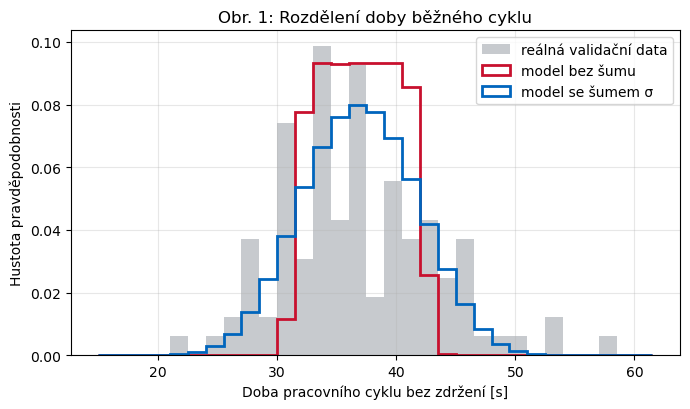

In [11]:
# Obr. 1: Rozdělení doby běžného cyklu (bez zdržení)
fig, ax = plt.subplots(figsize=(7, 4.2))
bins = np.arange(15, 62, 1.5)
ax.hist(bez, bins=bins, density=True, color='#9AA0A6', alpha=0.55, label='reálná validační data')
ax.hist(T_det, bins=bins, density=True, histtype='step', lw=2, color='#C8102E', label='model bez šumu')
ax.hist(T_det + sum_, bins=bins, density=True, histtype='step', lw=2, color='#0065BD', label='model se šumem σ')
ax.set_xlabel('Doba pracovního cyklu bez zdržení [s]')
ax.set_ylabel('Hustota pravděpodobnosti')
ax.set_title('Obr. 1: Rozdělení doby běžného cyklu')
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(f'{OUT}/SV_01_obr1_bezne_cykly.png', dpi=300)
plt.show()

## Část 5: Regresní experiment pro více náhodných rozdělení

Postup z Přílohy 6 (polynomiální regrese 3. stupně, predikce doby cyklu z délky trajektorie) je zopakován pro více náhodných rozdělení trénovacích dat. Doplněn je kontrolní experiment se stálou velikostí trénovací sady.

- **přidávání:** reálná trénovací data zůstávají, syntetická se přidávají (postup z práce),
- **stálá velikost:** velikost trénovací sady se nemění, reálná data se nahrazují syntetickými.

Testovací sadu tvoří ve všech bězích stejné nezávislé reálné cykly. Očekávané hodnoty pro seed 122: R² = 0,1673 (podíl 0) a 0,1941 (podíl 0,8).

In [12]:
def nacti_real(cesta):
    df = pd.read_csv(cesta)
    df['dist'] = df.apply(lambda r: calculation_dist(r['x'], r['y'], r['z']), axis=1)
    return remove_outliers_iqr(df[['dist', 'total_time']])

reg_train = nacti_real(f'{DATA}/06_AI/train/train_timelaps.csv')
reg_test = nacti_real(f'{DATA}/06_AI/val/valid_timelaps.csv')        # nezávislé reálné cykly
reg_syn = remove_outliers_iqr(syn)

def vyhodnot(train):
    m = model_poly().fit(train[['dist']], train['total_time'])
    pred = m.predict(reg_test[['dist']])
    return r2_score(reg_test['total_time'], pred), mean_squared_error(reg_test['total_time'], pred) ** 0.5

# Kontrola: seed 122 má dát hodnoty z práce
tr, _ = train_test_split(reg_train, test_size=0.2, random_state=SEED)
for podil in [0.0, 0.8]:
    s = int(len(tr) * podil / (1 - podil))
    r2, rmse = vyhodnot(pd.concat([tr, reg_syn.sample(n=s, random_state=SEED)]))
    print(f'Kontrola, seed {SEED}, podíl {podil}: n = {len(tr) + s}, R² = {r2:.4f}, RMSE = {rmse:.2f} s')

Kontrola, seed 122, podíl 0.0: n = 121, R² = 0.1673, RMSE = 5.90 s
Kontrola, seed 122, podíl 0.8: n = 605, R² = 0.1941, RMSE = 5.80 s


In [13]:
radky = []
for seed in range(N_SEEDU):
    tr, _ = train_test_split(reg_train, test_size=0.2, random_state=seed)
    n = len(tr)
    # přidávání: reálná data zůstávají, syntetická se přidávají
    for podil in PODILY:
        s = int(n * podil / (1 - podil))
        train = pd.concat([tr, reg_syn.sample(n=s, random_state=seed)])
        r2, rmse = vyhodnot(train)
        radky.append(dict(experiment='přidávání', seed=seed, podil=podil, n_train=len(train), r2=r2, rmse=rmse))
    # stálá velikost: reálná data se nahrazují syntetickými
    for podil in PODILY_STALA:
        n_syn = int(round(n * podil))
        train = pd.concat([tr.sample(n=n - n_syn, random_state=seed), reg_syn.sample(n=n_syn, random_state=seed)])
        r2, rmse = vyhodnot(train)
        radky.append(dict(experiment='stálá velikost', seed=seed, podil=podil, n_train=len(train), r2=r2, rmse=rmse))
regrese = pd.DataFrame(radky)
regrese.to_csv(f'{OUT}/SV_01_regrese_vsechny_behy.csv', index=False)

# Souhrn: průměr a směrodatná odchylka přes náhodná rozdělení
regrese_souhrn = regrese.groupby(['experiment', 'podil']).agg(
    n_train=('n_train', 'first'), r2_prumer=('r2', 'mean'), r2_sd=('r2', 'std'),
    rmse_prumer=('rmse', 'mean'), rmse_sd=('rmse', 'std'))
regrese_souhrn.to_csv(f'{OUT}/SV_01_regrese_souhrn.csv')
regrese_souhrn.round(4)

n_train  r2_prumer   r2_sd  rmse_prumer  rmse_sd
experiment     podil                                                  
přidávání      0.00       121     0.1653  0.0194       5.9068   0.0684
               0.10       134     0.1718  0.0152       5.8839   0.0540
               0.20       151     0.1773  0.0122       5.8645   0.0436
               0.30       172     0.1816  0.0101       5.8490   0.0361
               0.40       201     0.1854  0.0076       5.8356   0.0272
               0.50       242     0.1886  0.0051       5.8243   0.0183
               0.60       302     0.1908  0.0033       5.8163   0.0118
               0.70       403     0.1922  0.0019       5.8111   0.0068
               0.80       605     0.1930  0.0011       5.8085   0.0040
               0.90      1210     0.1930  0.0006       5.8084   0.0023
               0.95      2419     0.1926  0.0003       5.8098   0.0012
               0.99     12099     0.1922  0.0001       5.8113   0.0004
stálá velikost 0.00       121     0.1653  0.0194       5.9068   0.0684
               0.10       121     0.1705  0.0168       5.8886   0.0594
               0.20       121     0.1713  0.0176       5.8857   0.0621
               0.30       121     0.1733  0.0178       5.8784   0.0633
               0.40       121     0.1748  0.0158       5.8731   0.0560
               0.50       121     0.1796  0.0143       5.8560   0.0508
               0.60       121     0.1819  0.0093       5.8482   0.0331
               0.70       121     0.1849  0.0076       5.8375   0.0274
               0.80       121     0.1864  0.0062       5.8320   0.0222
               0.90       121     0.1890  0.0041       5.8228   0.0145

In [14]:
# Párové zlepšení R² proti trénování jen na reálných datech (stejné náhodné rozdělení)
radky = []
for exp in ['přidávání', 'stálá velikost']:
    t = regrese[regrese['experiment'] == exp].pivot(index='seed', columns='podil', values='r2')
    for podil in [0.6, 0.8]:
        d = t[podil] - t[0.0]
        radky.append({'experiment': exp, 'podíl': podil, 'průměrné zlepšení R²': d.mean(), 'sd': d.std(),
                      'běhů se zlepšením': int((d > 0).sum()), 'běhů celkem': len(d)})
regrese_parove = pd.DataFrame(radky).set_index(['experiment', 'podíl'])
regrese_parove.to_csv(f'{OUT}/SV_01_regrese_parove.csv')
regrese_parove.round(4)

průměrné zlepšení R²      sd  běhů se zlepšením  \
experiment     podíl                                                    
přidávání      0.6                  0.0255  0.0166                 30   
               0.8                  0.0277  0.0188                 29   
stálá velikost 0.6                  0.0166  0.0202                 24   
               0.8                  0.0211  0.0211                 25   

                      běhů celkem  
experiment     podíl               
přidávání      0.6             30  
               0.8             30  
stálá velikost 0.6             30  
               0.8             30

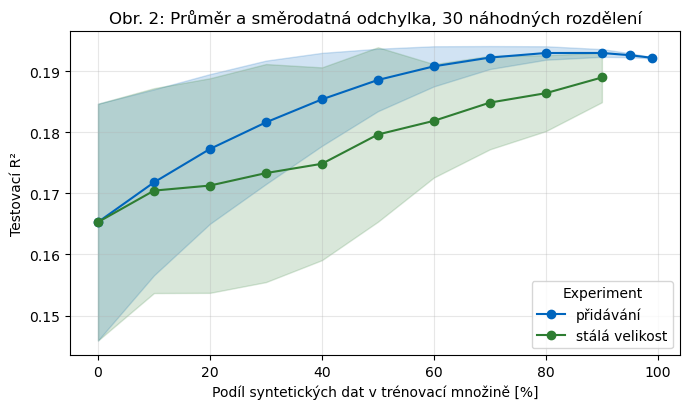

In [15]:
# Obr. 2: Testovací R² podle podílu syntetických dat
fig, ax = plt.subplots(figsize=(7, 4.2))
for exp, barva in [('přidávání', '#0065BD'), ('stálá velikost', '#2E7D32')]:
    g = regrese[regrese['experiment'] == exp].groupby('podil')['r2'].agg(['mean', 'std'])
    ax.plot(g.index * 100, g['mean'], 'o-', color=barva, label=exp)
    ax.fill_between(g.index * 100, g['mean'] - g['std'], g['mean'] + g['std'], color=barva, alpha=0.18)
ax.set_xlabel('Podíl syntetických dat v trénovací množině [%]')
ax.set_ylabel('Testovací R²')
ax.set_title(f'Obr. 2: Průměr a směrodatná odchylka, {N_SEEDU} náhodných rozdělení')
ax.legend(title='Experiment'); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(f'{OUT}/SV_01_obr2_regrese_seedy.png', dpi=300)
plt.show()

## Shrnutí výsledků

Hodnoty z běhu dne 2026-11-16.

**Část 1 – reprodukce.** Původní hodnoty testu K–S (0,0 % a 75,2 %) i regresního experimentu (R² 0,1673 a 0,1941, RMSE 5,90 a 5,80 s) se podařilo zopakovat.

**Část 2 – test K–S se stejným nastavením** (podíl opakování bez zamítnutí shody, proti 108 validačním cyklům):

| Velikost podvzorku | Před kalibrací, celý rozsah | Před kalibrací, stejný rozsah | Po kalibraci |
|---|---|---|---|
| 36 | 16,8 % | 83,3 % | 75,2 % |
| 54 | 4,0 % | 67,3 % | 47,9 % |
| 108 | 0,0 % | 7,0 % | 0,2 % |

Hodnota 75,2 % platí pro podvzorky o velikosti 36. Při plné velikosti validační sady test rozdíl ve tvaru rozdělení odhalí. Nízké hodnoty před kalibrací v celém rozsahu jsou dány především delšími trajektoriemi v simulaci.

**Část 3 – model před kalibrací ve stejném rozsahu trajektorií:**

| Simulace před kalibrací | Průměr | Welch p | Cohen d |
|---|---|---|---|
| celý rozsah, proti kalibračním datům | 46,49 s | 0,037 | 0,184 |
| stejný rozsah, proti kalibračním datům | 41,36 s | 0,766 | 0,027 |
| stejný rozsah, proti validačním datům | 41,14 s | 0,811 | 0,027 |

Reálný průměr je 41,99 s (kalibrační data) a 41,80 s (validační data). Ve stejném rozsahu trajektorií se průměr modelu shoduje s měřením už před kalibrací.

**Část 4 – generátor s reziduálním šumem** (proti 108 validačním cyklům):

| Ukazatel | Bez šumu | Se šumem σ |
|---|---|---|
| Průměr / sd | 41,32 s / 20,25 s | 41,32 s / 20,57 s |
| Welch p | 0,862 | 0,862 |
| Mann–Whitney p | 0,255 | 0,359 |
| K–S bez zamítnutí, n = 36 | 73,6 % | 92,7 % |
| K–S bez zamítnutí, n = 54 | 47,9 % | 92,2 % |
| K–S bez zamítnutí, n = 108 | 0,1 % | 86,2 % |
| Pokrytí 95% intervalu | 77,8 % | 92,6 % |

Běžné cykly bez zdržení: reálná sd 6,44 s, model bez šumu 3,15 s, model se šumem 4,77 s. Zdržení: v reálných datech 9,3 % cyklů a 5,32 s na cyklus, v modelu 7,1 % cyklů a 4,38 s na cyklus.

Doplnění reziduálního šumu výrazně zlepšuje shodu tvaru rozdělení i pokrytí intervalu. Celková směrodatná odchylka zůstává podhodnocena (reálná 28,46 s), protože model generuje zdržení méně často a kratší.

**Část 5 – regresní experiment, 30 náhodných rozdělení:**

| Experiment | R² při podílu 0 | R² při podílu 0,8 | Párové zlepšení | Běhů se zlepšením |
|---|---|---|---|---|
| přidávání | 0,165 ± 0,019 | 0,193 ± 0,001 | +0,028 | 29 z 30 |
| stálá velikost (121 cyklů) | 0,165 ± 0,019 | 0,186 ± 0,006 | +0,021 | 25 z 30 |

Zlepšení predikce se opakuje téměř ve všech náhodných rozděleních. Nastává i při stálé velikosti trénovací sady, není tedy dáno jen větším počtem záznamů. Od podílu přibližně 60 % jsou rozdíly menší než rozptyl mezi běhy.

## Omezení

- Jde o dodatečnou analýzu provedenou po odevzdání práce. Syntetická data použitá v práci a v regresním experimentu reziduální šum neobsahují.
- Všechny výpočty se týkají jednoho robotického systému a jedné predikované veličiny.
- Testovací sada je ve všech bězích regresního experimentu stejná. Rozptyl mezi běhy vyjadřuje vliv rozdělení trénovacích dat a výběru syntetických vzorků.

## Autor / Organizace / Datum

Vjačeslav Usmanov, ČVUT v Praze, Fakulta stavební

## Přehled změn

| Datum (YYYY-MM-DD) | Verze | Autor změny | Popis změny |
|---|---|---|---|
| 2026-11-16 | 1.0 | Vjačeslav Usmanov | added SV_01_Supplementary_Validation.ipynb |